In [17]:
import pandas as pd
import os
import zipfile
from pathlib import Path
import numpy as np
import re
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

* Variables and Functions setup

In [18]:
zip_folder = 'raw_data'
data_folder = 'extracted_data'
survey_year_79 = [y for y in range(1979,2023) if y not in [1995, 1997, 1999, 2001, 2003, 2005, 2007, 2009, 2011, 2013, 2015, 2017, 2019, 2021]]
survey_year_97 = [y for y in range(1997,2024) if y not in [2012,2014,2016,2018,2020,2022]]
race_mapping = {
    3: 'White', 5: 'White', 6: 'White', 7: 'White', 11: 'White', 12: 'White', 
    22: 'White', 23: 'White', 24: 'White', 25: 'White', 27: 'White', 29: 'White', 
    1: 'Black',
    15: 'Hispanic', 16: 'Hispanic', 17: 'Hispanic', 18: 'Hispanic', 19: 'Hispanic', 
    20: 'Hispanic', 21: 'Hispanic',
    2: 'Asian/PI', 4: 'Asian/PI', 8: 'Asian/PI', 10: 'Asian/PI', 13: 'Asian/PI', 
    14: 'Asian/PI', 26: 'Asian/PI',
    0: 'Native/Other', 9: 'Native/Other', 28: 'Native/Other' 
}
sex_mapping = {1:0, 2:1}

In [19]:
def create_rnum_dict(file_path):
    rnum_to_var = {}
    pattern = re.compile(r"^([A-Za-z0-9]+\.\d{2}[A-Za-z0-9]*)\s+\[(.*?)\]\s+Survey Year:\s*(.*)")
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as file:
        for line in file:
            match = pattern.search(line.strip())
            if match:
                rnum = re.sub(r'[^a-zA-Z0-9]', '', match.group(1))
                var_name = match.group(2)
                survey_year_79 = match.group(3).strip()
                if re.match(r"^\d{4}$", survey_year_79):
                    var_name = f"{var_name}_{survey_year_79}"
                rnum_to_var[rnum] = var_name     
    return rnum_to_var

def rename_columns(col):
    if 'EMPLOYERS_ALL_' in col:
        clean_name = col.replace('EMPLOYERS_ALL_', '')
        parts = clean_name.split('.')
        var_year = parts[0].rsplit('_', 1)
        return f"{var_year[0]}.{parts[1]}_{var_year[1]}"
    if 'CASEID' in col:
        return 'CASEID'
    if 'HGCREV' in col:
        parts = col.split('_')
        return f"{parts[0][:-2]}_{parts[1]}"
    if 'FAM-30_1_1979' in col:
        return 'race'
    if 'SAMPLE_SEX_1979' in col:
        return 'sex'
    return col

* Occupation major grouping maping

In [20]:
occ70_dict = {}
for x in range(0, 196):
    occ70_dict[x] = "Professional"
for x in range(201, 246):
    occ70_dict[x] = "Managers"
for x in range(260,281):
    occ70_dict[x] = "Sales"
for x in range(301,396):
    occ70_dict[x] = "Clerical"
for x in range(401,581):
    occ70_dict[x] = "Craftsmen"
# for x in range(601,727):
#     occ70_dict[x] = "Operatives"
# for x in range(740,786):
#     occ70_dict[x] = "Laborers"
for x in range(601,786):
    occ70_dict[x] = "Operatives and Laborers"
for x in range(901,985):
    occ70_dict[x] = "Service"

    
occ00_dict = {}
# Professional
for x in [range(62,71),80,82,93,range(100,352),353,354,361,362,363,462,493,601,903,904]:
    if type(x) is int:
        occ00_dict[x] = "Professional"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Professional"
# Managers
for x in [range(0,54),56,72,73,83,range(84,92),94,95,931]:
    if type(x) is int:
        occ00_dict[x] = "Managers"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Managers"
# Sales
for x in [range(475,493),range(494,497)]:
    if type(x) is int:
        occ00_dict[x] = "Sales"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Sales"
# Clerical
for x in [54,60,81,472,474,500,range(510,556),range(556,594)]:
    if type(x) is int:
        occ00_dict[x] = "Clerical"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Clerical"
# Craftsmen
for x in [352,441,range(621,626),range(630,637),range(642,654),range(666,672),674,676,range(700,761),range(762,771),774,780,803,806,813,816,range(823,826),
          833,835,844,845,range(850,853),range(860,864),875,876,891,900,920,941,range(951,957)]:
    if type(x) is int:
        occ00_dict[x] = "Craftsmen"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Craftsmen"
# # Operatives
# for x in [range(501,504),640,range(680,692),694,range(771,774),775,range(781,803),804,range(810,813),814,815,range(820,823),range(826,833),834,range(836,843),846,range(853,856),
#           range(864,875),range(880,891),range(892,895),896,range(911,916),923,933,935,936,942,950,960,964,965,973]:
#     if type(x) is int:
#         occ00_dict[x] = "Operatives"
#     elif type(x) is range:
#         for n in x:
#             occ00_dict[n] = "Operatives"
# # Laborers
# for x in [421,425,434,435,600,range(602,614),626,660,672,673,675,692,693,761,895,range(961,964),972,974,975]:
#     if type(x) is int:
#         occ00_dict[x] = "Laborers"
#     elif type(x) is range:
#         for n in x:
#             occ00_dict[n] = "Laborers"
# Operatives and Laborers
for x in [range(501,504),640,range(680,692),694,range(771,774),775,range(781,803),804,range(810,813),814,815,range(820,823),range(826,833),834,range(836,843),846,range(853,856),
          range(864,875),range(880,891),range(892,895),896,range(911,916),923,933,935,936,942,950,960,964,965,973,421,425,434,435,600,range(602,614),626,660,672,673,675,692
          ,693,761,895,range(961,964),972,974,975]:
    if type(x) is int:
        occ00_dict[x] = "Operatives and Laborers"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Operatives and Laborers"
# Service
for x in [360,364,365,range(370,421),range(422,425),430,432,range(442,462),464,465,934]:
    if type(x) is int:
        occ00_dict[x] = "Service"
    elif type(x) is range:
        for n in x:
            occ00_dict[n] = "Service"

* Extracting files from zip files in raw_data folder

In [21]:
files = [f.name for f in Path(zip_folder).iterdir() if f.is_file()]
zip_file = [os.path.join(zip_folder, x) for x in files if x.endswith('.zip')]
for file in zip_file:
    with zipfile.ZipFile(file, 'r') as archive:
        for f in archive.namelist():
            if f.endswith((".cdb", ".csv")):
                archive.extract(f, data_folder)
            elif f.endswith((".NLSY79","NLSY97")):
                archive.extract(f, 'data_tags')

* Generating csv map

In [22]:
# Create diction of CPI, base year as 2020
df_cpi = pd.read_csv('cpi.csv')
df_cpi['observation_date'] = df_cpi['observation_date'].str[:4].astype(int)
base = df_cpi.loc[df_cpi['observation_date'] == 2020, 'CPIAUCSL'].values[0]
df_cpi['ratio'] = base / df_cpi['CPIAUCSL']
cpi_map = df_cpi.set_index('observation_date')['ratio'].to_dict()

#### NLSY79

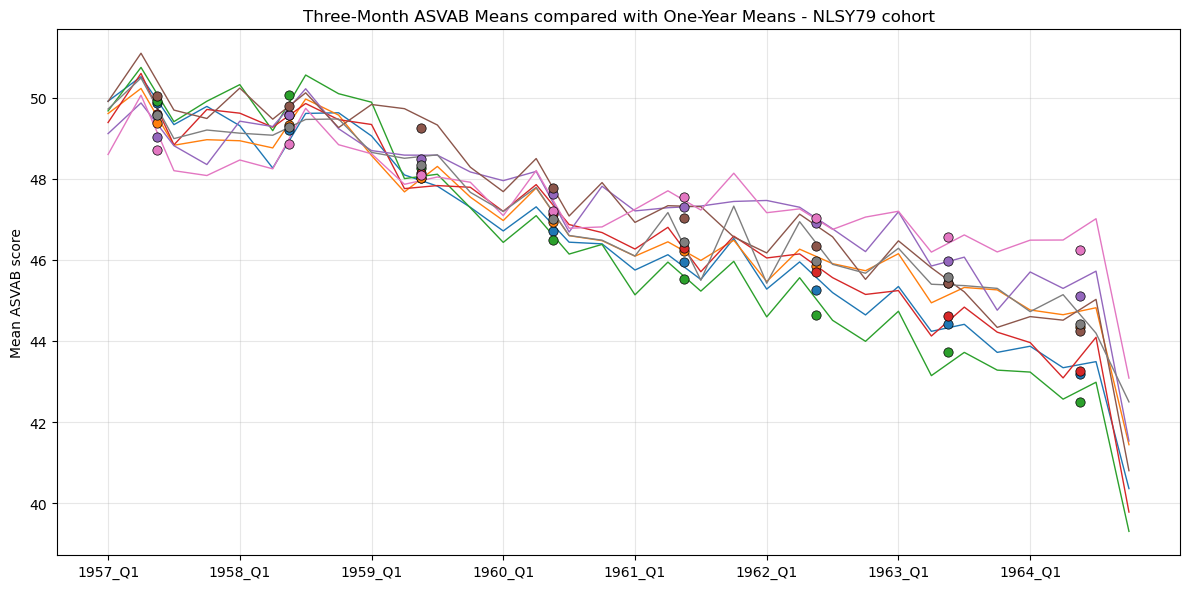

Variance explained by PC1: 0.686


In [23]:
df_79ability = pd.read_csv(os.path.join(data_folder, 'nlsy79.csv'))
abilty79_rename_dict = create_rnum_dict(os.path.join(data_folder, 'nlsy79.cdb'))
df_79ability = df_79ability.rename(columns = abilty79_rename_dict)
df_79ability = df_79ability.replace([-1, -2, -3, -4,-5], np.nan)
df_79ability = df_79ability.rename(columns=rename_columns)
df_79ability['Q1-3_A~Y_1979'] = df_79ability['Q1-3_A~Y_1979']+1900
asvab_cols = [c for c in df_79ability.columns if c.startswith("ASVAB")]

# Comparing between 3 month grouping and one year grouping

df_79ability["group_3month"] = (df_79ability["Q1-3_A~Y_1979"].astype(str) + "_Q" + (((df_79ability["Q1-3_A~M_1979"] - 1) // 3) + 1).astype(str))

mean1 = (df_79ability.groupby("group_3month")[asvab_cols].mean().sort_index())
mean2 = (df_79ability.groupby("Q1-3_A~Y_1979")[asvab_cols].mean().sort_index())

ax = mean1.plot(figsize=(12, 6),linewidth=1)

year_positions = {}
for position, group_label in enumerate(mean1.index):
    year = str(group_label).split("_")[0]
    year_positions.setdefault(year, []).append(position)

year_positions = {year: np.mean(positions) for year, positions in year_positions.items()}

for column, line in zip(asvab_cols, ax.lines):
    x_dots = []
    y_dots = []
    for year, value in mean2[column].items():
        year_key = str(int(year))
        if year_key in year_positions and pd.notna(value):
            x_dots.append(year_positions[year_key])
            y_dots.append(value)
    ax.scatter(x_dots, y_dots, color=line.get_color(), edgecolor="black", linewidth=0.5,
        s=45, zorder=5, label="_nolegend_")
q1_positions = [i for i, label in enumerate(mean1.index) if str(label).upper().endswith("_Q1")]
q1_labels = [str(mean1.index[i]).upper() for i in q1_positions]
ax.set_xlabel("")
ax.set_xticks(q1_positions)
ax.set_xticklabels(q1_labels, rotation=0)
ax.set_ylabel("Mean ASVAB score")
ax.set_title("Three-Month ASVAB Means compared with One-Year Means - NLSY79 cohort")
ax.get_legend().remove()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Normalization of ASVAB scores using Three-Year age group
std_cols = [f"{col}_std" for col in asvab_cols]
df_79ability[std_cols] = (df_79ability.groupby("group_3month")[asvab_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=1)))
# df_79ability[std_cols].plot.density()

# Applying PCA analysis
valid_r = df_79ability[std_cols].notna().all(axis=1)
valid_df = df_79ability.loc[valid_r, std_cols]
pca = PCA(n_components=2)
pca_scores = pca.fit_transform(valid_df)
print("Variance explained by PC1:", f"{pca.explained_variance_ratio_[0]:.3f}")
df_79ability["ASVAB"] = np.nan
df_79ability.loc[valid_r, "ASVAB"] = pca_scores[:, 0]
df_79ability["ASVAB"] = (df_79ability["ASVAB"].rank(pct=True) * 100)

df_79ability.drop(columns=asvab_cols+std_cols+["group_3month"], inplace=True)

for y in survey_year_79:
    df_79ability[f'age_{y}'] = y - df_79ability['Q1-3_A~Y_1979']
df_79ability = df_79ability.drop(columns=['Q1-3_A~M_1979','Q1-3_A~Y_1979'])

df_79ability['race'] = df_79ability['race'].map(race_mapping)
df_79ability['sex'] = df_79ability['sex'].map(sex_mapping)

# Wage (real and handling extrodinary values)
wage_cols = [f'HRLY_WAGE.01_{y}' for y in survey_year_79] + [f'HRLY_WAGE.02_{y}' for y in survey_year_79]
for col in wage_cols:
    year = int(col[-4:])
    df_79ability[col] = df_79ability[col] * cpi_map[year] / 100

# Adjusting occupation to 8 major groups
occ70_cols = [c for c in df_79ability.columns if c.startswith("OCC")]
for c in occ70_cols:
    original = df_79ability[c].copy()
    if int(c[-4:]) < 2002:
        df_79ability[c] = original.map(occ70_dict)
    elif int(c[-4:]) == 2002:
        df_79ability[c] = original.map(occ00_dict)
    elif int(c[-4:]) > 2002:
        df_79ability[c] = (original / 10).map(occ00_dict)

# Drop unnecessary columns 
df_79ability = df_79ability.drop(columns=['SAMPLE_ID_1979','SAMPLE_RACE'])
# Job-specific variable prefixes
year_stubs = ['TENURE.01', 'TENURE.02', 'HOURSWEEK.01', 'HOURSWEEK.02', 'OCC.01', 'OCC.02', 'COW.01', 'COW.02', 'HRLY_WAGE.01', 'HRLY_WAGE.02', 'SAMPWEIGHT', 'HGCREV', 'age']
df79_year_long = (pd.wide_to_long(df_79ability,stubnames=year_stubs,i='CASEID',j='year',sep='_',suffix=r'\d{4}').reset_index())
job_stubs = ['TENURE','HOURSWEEK','OCC','COW','HRLY_WAGE']
df79_long = (pd.wide_to_long(df79_year_long,stubnames=job_stubs,i=['CASEID', 'year'],j='job_num',sep='.',suffix=r'\d+').reset_index())
df79_long['job_num'] = df79_long['job_num'].astype(int)
df79_long = df79_long.dropna(subset=job_stubs,how='all')
df79_long = df79_long.sort_values(['CASEID', 'year', 'job_num']).reset_index(drop=True)
df79_long = df79_long[df79_long['SAMPWEIGHT'] != 0].copy()
df79_long['SAMPWEIGHT'] = df79_long['SAMPWEIGHT'] / 100

In [31]:
x = df79_long['OCC'].count()
df79_long['OCC'].value_counts()/x

OCC
Operatives and Laborers    0.255647
Service                    0.254325
Clerical                   0.216899
Craftsmen                  0.093474
Professional               0.070089
Managers                   0.060174
Sales                      0.049393
Name: count, dtype: float64

In [25]:
df_long1 = df79_long.copy()
start_len = len(df_long1)
print('Original Sample Size:', start_len)

df_long1.dropna(subset=['race', 'sex', 'age'], how='any', inplace=True)
print('demographic', len(df_long1), round(len(df_long1)*100/start_len,2))

df_long1.dropna(subset=['ASVAB'],inplace=True)
print('ASVAB', len(df_long1), round(len(df_long1)*100/start_len,2))

df_long1 = df_long1[df_long1['COW'] != 4]
print('Exclude Self-employed workers', len(df_long1), round(len(df_long1)*100/start_len,2))

df_long1.dropna(subset=['HGCREV'],inplace=True)
print('educ', len(df_long1), round(len(df_long1)*100/start_len,2))

df_long1.dropna(subset=['HRLY_WAGE'], inplace=True)
print('Wage observed', len(df_long1), round(len(df_long1)*100/start_len, 2))

df_long1.loc[(df_long1['HOURSWEEK'] < 35) | (df_long1['HOURSWEEK'].isna()), 'TENURE'] = np.nan
df_long1['LOG_WAGE'] = np.log(df_long1['HRLY_WAGE'].where(df_long1['HRLY_WAGE'] > 0))
df_long1.dropna(subset=['LOG_WAGE'], inplace=True)
print('Fulltime and log wage', len(df_long1), round(len(df_long1)*100/start_len, 2))

df_long1.dropna(subset=['TENURE'], inplace=True)
print('Experience', len(df_long1), round(len(df_long1)*100/start_len, 2))

df_long1.dropna(subset=['OCC'], inplace=True)
print('Occupation', len(df_long1), round(len(df_long1)*100/start_len, 2))

# Making experience of job>=2 correct
last_tenure_job1 = (df_long1.loc[df_long1["job_num"] == 1, ["CASEID", "year", "TENURE"]].dropna(subset=["TENURE"]).sort_values(["CASEID", "year"]).groupby("CASEID")["TENURE"].last())
job1_offset = df_long1["CASEID"].map(last_tenure_job1)
mask = df_long1["job_num"] == 2
df_long1.loc[mask, "TENURE"] = (df_long1.loc[mask, "TENURE"]+ job1_offset[mask].fillna(0))
df_long1.rename(columns={'TENURE':'EXPERIENCE'}, inplace=True)

# Generate Lagged occ and wage
df_long1 = (df_long1.sort_values(["CASEID", "year", "job_num"]).reset_index(drop=True))
g = df_long1.groupby("CASEID", sort=False)
df_long1["OCC_L1"] = g["OCC"].shift(1)
df_long1["OCC_L2"] = g["OCC"].shift(2)
df_long1["LOG_WAGE_L1"] = g["LOG_WAGE"].shift(1)
df_long1["LOG_WAGE_L2"] = g["LOG_WAGE"].shift(2)

Original Sample Size: 56039
demographic 55511 99.06
ASVAB 52535 93.75
Exclude Self-employed workers 51907 92.63
educ 51499 91.9
Wage observed 40490 72.25
Fulltime and log wage 40487 72.25
Experience 26262 46.86
Occupation 25231 45.02


* Export to csv file

In [26]:
df_long1.to_csv(os.path.join('cleaned', 'nlsy79_cleaned_2.csv'), index=False)

#### NLSY97

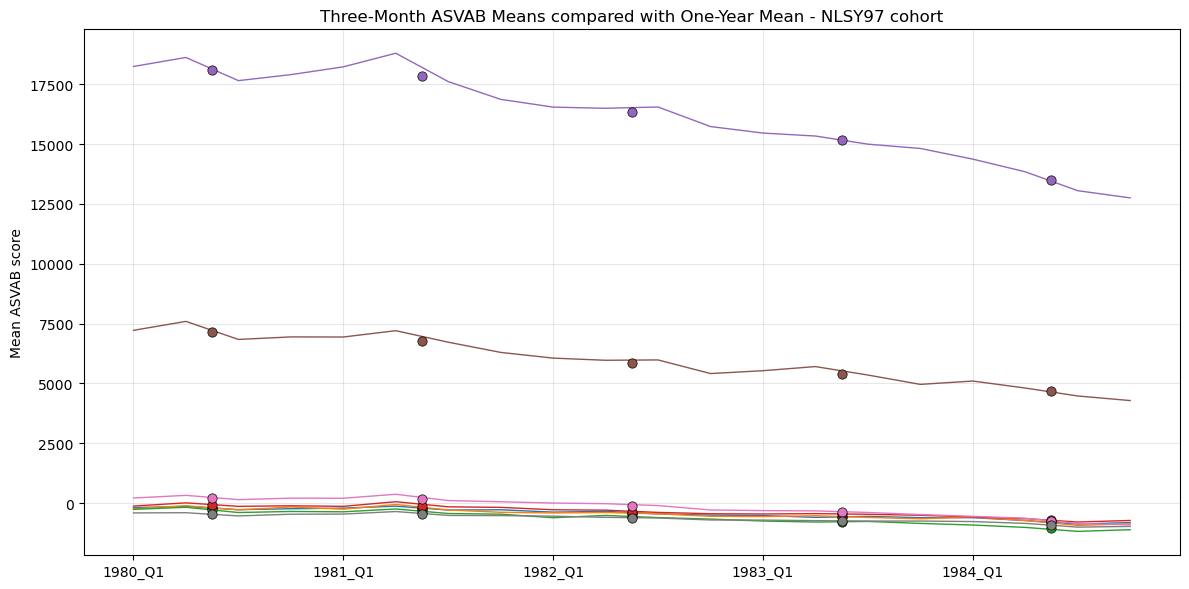

In [27]:
df_97ability = pd.read_csv(os.path.join(data_folder, '97-ability.csv'))
abilty97_rename_dict = create_rnum_dict(os.path.join(data_folder, '97-ability.cdb'))
df_97ability = df_97ability.rename(columns = abilty97_rename_dict)
df_97ability = df_97ability.replace([-1, -2, -3, -4,-5], np.nan)
asvab_cols = [c for c in df_97ability.columns if c.startswith("ASVAB")]
subtests = ["GS", "AR", "WK", "PC", "NO", "CS", "MK", "MC"]
for test in subtests:
    pos = f"ASVAB_{test}_ABILITY_EST_POS"
    neg = f"ASVAB_{test}_ABILITY_EST_NEG"
    df_97ability[f"ASVAB_{test}"] = df_97ability[pos].combine_first(-df_97ability[neg])
    df_97ability = df_97ability.drop(columns=[pos,neg])
asvab_cols = [c for c in df_97ability.columns if c.startswith("ASVAB")]

# Comparing between 3 month grouping and one year grouping

df_97ability["group_3month"] = (df_97ability["KEY!BDATE_Y_1997"].astype(str) + "_Q" + (((df_97ability["KEY!BDATE_M_1997"] - 1) // 3) + 1).astype(str))

mean1 = (df_97ability.groupby("group_3month")[asvab_cols].mean().sort_index())
mean2 = (df_97ability.groupby("KEY!BDATE_Y_1997")[asvab_cols].mean().sort_index())

ax = mean1.plot(figsize=(12, 6),linewidth=1)

year_positions = {}
for position, group_label in enumerate(mean1.index):
    year = str(group_label).split("_")[0]
    year_positions.setdefault(year, []).append(position)

year_positions = {year: np.mean(positions) for year, positions in year_positions.items()}

for column, line in zip(asvab_cols, ax.lines):
    x_dots = []
    y_dots = []
    for year, value in mean2[column].items():
        year_key = str(int(year))
        if year_key in year_positions and pd.notna(value):
            x_dots.append(year_positions[year_key])
            y_dots.append(value)
    ax.scatter(x_dots, y_dots, color=line.get_color(), edgecolor="black", linewidth=0.5,
        s=45, zorder=5, label="_nolegend_")
q1_positions = [i for i, label in enumerate(mean1.index) if str(label).upper().endswith("_Q1")]

q1_labels = [str(mean1.index[i]).upper() for i in q1_positions]
ax.set_xlabel("")
ax.set_xticks(q1_positions)
ax.set_xticklabels(q1_labels, rotation=0)
ax.set_ylabel("Mean ASVAB score")
ax.set_title("Three-Month ASVAB Means compared with One-Year Mean - NLSY97 cohort")
ax.get_legend().remove()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Normalization of ASVAB scores using Three- age group
std_cols = [f"{col}_std" for col in asvab_cols]
df_97ability[std_cols] = (df_97ability.groupby("group_3month")[asvab_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=1)))

# Applying PCA analysis
asvab_std_cols = [c for c in df_97ability.columns if c.startswith("ASVAB")]
valid_r = df_97ability[asvab_std_cols].notna().all(axis=1)
valid_df = df_97ability.loc[valid_r, asvab_std_cols]
scaler = StandardScaler()
scaled_asvab = scaler.fit_transform(valid_df)

pca = PCA(n_components=2)
pca_scores = pca.fit_transform(scaled_asvab)
print("Variance explained by PC1:", f"{pca.explained_variance_ratio_[0]:.3f}")
df_97ability['ASVAB'] = np.nan
df_97ability.loc[valid_r,'ASVAB'] = pca_scores[:, 0]
df_97ability['ASVAB'] = df_97ability['ASVAB'].rank(pct=True) * 100

df_97ability.drop(columns=asvab_cols+asvab_std_cols+["group_3month"], inplace=True)
df_97ability

Variance explained by PC1: 0.664


,PUBID_1997,KEY!BDATE_M_1997,KEY!BDATE_Y_1997,ASVAB
0,1,9,1981,53.039384
1,2,7,1982,69.948630
2,3,9,1983,34.902968
3,4,2,1981,54.223744
4,5,10,1982,NaN
...,...,...,...,...
8979,9018,3,1980,18.892694
8980,9019,9,1984,27.597032
8981,9020,7,1980,96.575342
8982,9021,7,1980,66.609589
